# Лабораторная работа №2: Метод ломаных (Метод Пиявского)
- Блинова Полина Вячеславовна
- Ису 465232
- Группа К3339
- Год 2026/2027
# 1. Теория
## Метод ломаных (Пиявского)

Метод ломаных (Пиявского) — детерминированный метод глобальной оптимизации для липшицевых функций на отрезке $[a, b]$.

## Липшицева функция

Функция с константой $L$:

$$|f(x_1) - f(x_2)| \le L|x_1 - x_2|, \quad \forall x_1, x_2 \in [a, b]$$

## Идея метода

Строим кусочно-линейную нижнюю огибающую (ломаную), используя оценку константы Липшица:

$$\varphi(x) = \max_k \left[ f(x_k) - L|x - x_k| \right]$$

## Точка нового испытания

Точка нового испытания — точка пересечения двух соседних «холмов» ломаной, где достигается минимум $\varphi(x)$ (или максимум — для поиска глобального максимума).

## Критерий остановки

Процесс продолжается, пока оценка не станет достаточно точной.

# 2. Реализация
## Импорты

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

## Разбор строки функции

In [ ]:
def parse_function(expression):
    expression = expression.strip()
    if expression.lower().startswith("f(x)"):
        expression = expression.split("=", 1)[1].strip()
    env = {
        "x": None, "np": np,
        "sin": np.sin, "cos": np.cos, "tan": np.tan,
        "exp": np.exp, "log": np.log, "sqrt": np.sqrt,
        "abs": np.abs, "pi": np.pi, "e": np.e,
        "arcsin": np.arcsin, "arccos": np.arccos, "arctan": np.arctan,
        "sinh": np.sinh, "cosh": np.cosh, "tanh": np.tanh,
    }
    def f(x):
        env["x"] = x
        return eval(expression, {"__builtins__": {}}, env)
    return f, expression

## Оценка константы Липшица

In [ ]:
def estimate_lipschitz(f, a, b, n=50000, safety=1.5):
    xs = np.linspace(a, b, n)
    ys = f(xs)
    L = np.max(np.abs(np.diff(ys)) / np.diff(xs))
    return L * safety

## Реализация метода ломаных

In [ ]:
def phi(x, pts, vals, L):
    return max(vals[k] - L * abs(x - pts[k]) for k in range(len(pts)))


def find_new_point(pts, vals, L):
    order = np.argsort(pts)
    xs_sorted = np.array(pts)[order]
    fs_sorted = np.array(vals)[order]

    best_x, best_phi = None, np.inf
    for i in range(len(xs_sorted) - 1):
        x1, x2 = xs_sorted[i], xs_sorted[i + 1]
        f1, f2 = fs_sorted[i], fs_sorted[i + 1]

        x_star = (f1 - f2 + L * (x1 + x2)) / (2 * L)

        if x1 < x_star < x2:
            phi_val = f1 - L * (x_star - x1)
            if phi_val < best_phi:
                best_phi, best_x = phi_val, x_star

    return best_x, best_phi


def pijavskii_method(f, a, b, eps, L=None, max_iter=10000):
    t0 = time.perf_counter()
    if L is None:
        L = estimate_lipschitz(f, a, b)

    pts = [a, b]
    vals = [f(a), f(b)]
    history = [(a, f(a)), (b, f(b))]

    iterations = 0
    while iterations < max_iter:
        iterations += 1
        x_new, phi_val = find_new_point(pts, vals, L)
        if x_new is None:
            break

        current_min = min(vals)
        phi_min_exact = min(current_min, phi_val)

        if current_min - phi_min_exact < eps:
            break

        f_new = f(x_new)
        pts.append(x_new)
        vals.append(f_new)
        history.append((x_new, f_new))

    t1 = time.perf_counter()
    idx = int(np.argmin(vals))
    return pts[idx], vals[idx], history, iterations, t1 - t0, L

## Тестовые функции
### Функция Растригина:

Функция имеет вид:
$$f(x) = A \cdot n + \sum_{i=1}^{n} \left[ x_i^2 - A\cos(2\pi x_i) \right]$$

где:

x = (x₁, x₂, ..., xₙ) — вектор переменных;

n — количество переменных (размерность пространства);

A — константа, обычно принимающая значение 10.

Диапазон поиска для каждой переменной обычно [-5.12, 5.12]

Подставляем $n = 1$.

Для одной переменной $x = x_1$ сумма состоит из одного слагаемого:

$$f(x) = A \cdot 1 + \left[ x^2 - A\cos(2\pi x) \right]$$

При $A = 10$:

$$f(x) = 10 + x^2 - 10\cos(2\pi x)$$

Переставим слагаемые:

$$f(x) = x^2 - 10\cos(2\pi x) + 10$$

### Функция Экли:

В общем виде для d-мерной области функция записывается так:

$$f(x) = -a \exp\left(-b \sqrt{\frac{1}{d} \sum_{i=1}^{d} x_i^2}\right) - \exp\left(\frac{1}{d} \sum_{i=1}^{d} \cos(c x_i)\right) + a + e$$

Стандартные параметры: $a = 20$, $b = 0.2$, $c = 2\pi$, $d$ — размерность.

Подставляем $y = 0$ (делаем срез)

Первое слагаемое

Внутри корня:

$$\frac{1}{2}(x^2 + y^2)\Big|_{y=0} = \frac{1}{2}(x^2 + 0) = \frac{1}{2}x^2 = 0.5\,x^2$$

Тогда первое слагаемое:

$$-20\exp\left(-0.2\sqrt{0.5\,x^2}\right)$$


Второе слагаемое

Внутри второй экспоненты:

$$\frac{1}{2}\big(\cos(2\pi x) + \cos(2\pi y)\big)\Big|_{y=0} = \frac{1}{2}\big(\cos(2\pi x) + \cos(0)\big)$$

Учитываем $\cos(0) = 1$:

$$= \frac{1}{2}\big(\cos(2\pi x) + 1\big) = \frac{1}{2}\cos(2\pi x) + \frac{1}{2} = 0.5\cos(2\pi x) + 0.5$$

Тогда второе слагаемое:

$$-\exp\big(0.5\cos(2\pi x) + 0.5\big)$$

Итоговая формула среза

$$f(x) = -20\exp\left(-0.2\sqrt{0.5\,x^2}\right) - \exp\big(0.5\cos(2\pi x) + 0.5\big) + 20 + e$$

In [ ]:
def rastrigin_1d(x):
    return x**2 - 10 * np.cos(2 * np.pi * x) + 10

def ackley_1d(x):
    return (-20 * np.exp(-0.2 * np.sqrt(0.5 * x**2))
            - np.exp(0.5 * np.cos(2 * np.pi * x) + 0.5)
            + 20 + np.e)

## Визуализация и вывод результатов

In [ ]:
def run_and_plot(f, a, b, eps, title, L=None):
    x_min, f_min, history, iters, elapsed, L_used = \
        pijavskii_method(f, a, b, eps, L=L)

    xs = np.linspace(a, b, 1000)
    ys = f(xs)

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(xs, ys, 'b-', lw=1.5, label="f(x)")

    hx = np.array([p[0] for p in history])
    hy = np.array([p[1] for p in history])
    grid = np.linspace(a, b, 400)
    phi_vals = [max(hy[k] - L_used * abs(g - hx[k]) for k in range(len(hx)))
                for g in grid]
    ax.plot(grid, phi_vals, 'g--', lw=1.2, label="нижняя огибающая (ломаная)")

    ax.scatter(hx, hy, c='red', s=25, zorder=5, label="точки испытаний")
    ax.scatter([x_min], [f_min], c='gold', edgecolors='black', s=180,
               marker='*', zorder=6,
               label=f"min ≈ ({x_min:.4f}, {f_min:.4f})")
    ax.axvline(x_min, color='orange', ls=':', alpha=0.7)

    ax.set_title(f"{title}\nL≈{L_used:.2f}, итераций: {iters}, "
                 f"время: {elapsed*1000:.1f} мс, eps={eps}")
    ax.set_xlabel("x"); ax.set_ylabel("f(x)")
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Приближённый аргумент минимума: x* ≈ {x_min:.6f}")
    print(f"Приближённое минимальное значение: f(x*) ≈ {f_min:.6f}")
    print(f"Число итераций: {iters}")
    print(f"Затраченное время: {elapsed*1000:.2f} мс")
    print(f"Оценка константы Липшица: L ≈ {L_used:.4f}")
    print("-" * 60)

## Запуск на тестовых функциях


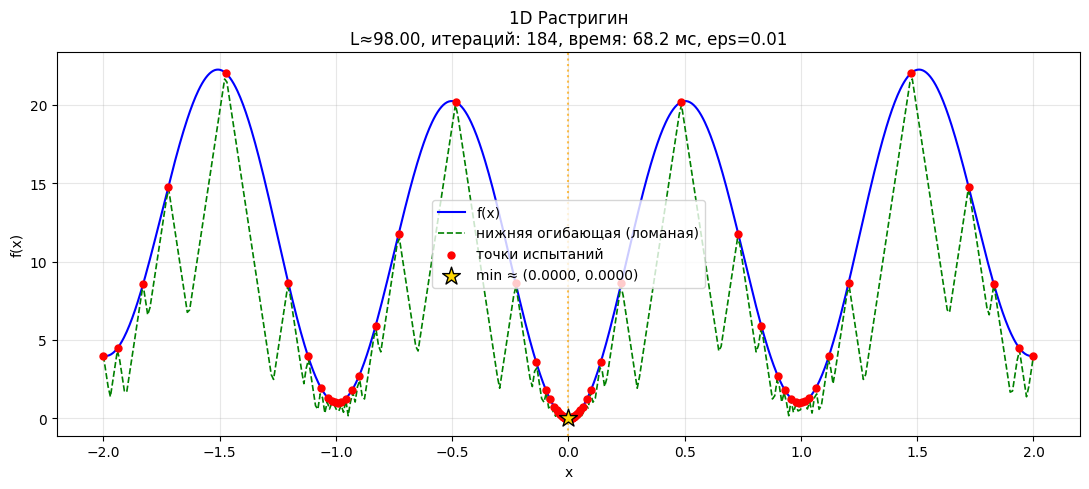

Приближённый аргумент минимума: x* ≈ 0.000000
Приближённое минимальное значение: f(x*) ≈ 0.000000
Число итераций: 184
Затраченное время: 68.15 мс
Оценка константы Липшица: L ≈ 97.9990
------------------------------------------------------------


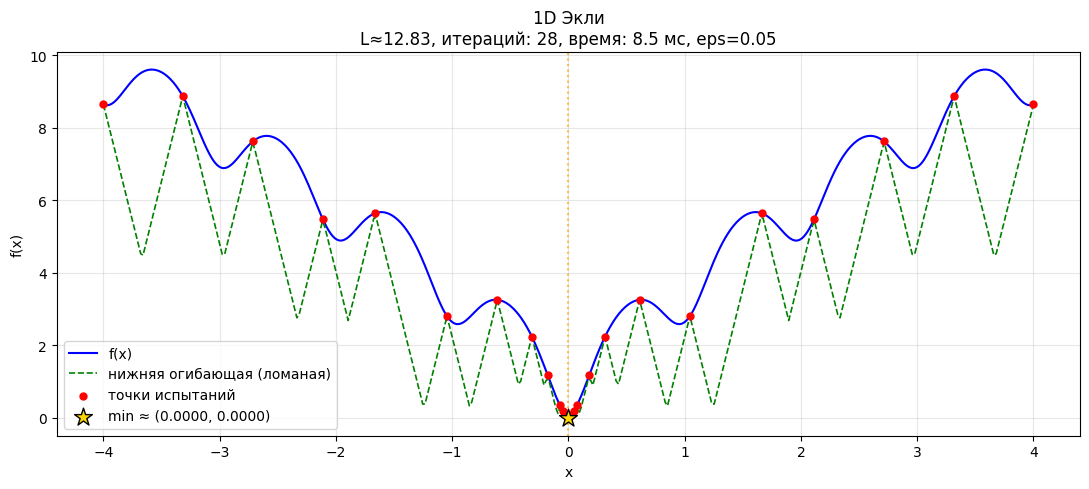

Приближённый аргумент минимума: x* ≈ 0.000000
Приближённое минимальное значение: f(x*) ≈ 0.000000
Число итераций: 28
Затраченное время: 8.48 мс
Оценка константы Липшица: L ≈ 12.8340
------------------------------------------------------------


In [ ]:
run_and_plot(rastrigin_1d, -2.0, 2.0, eps=0.01,
             title="1D Растригин")

run_and_plot(ackley_1d, -4.0, 4.0, eps=0.05,
             title="1D Экли")

## Запуск с пользовательской строкой функции

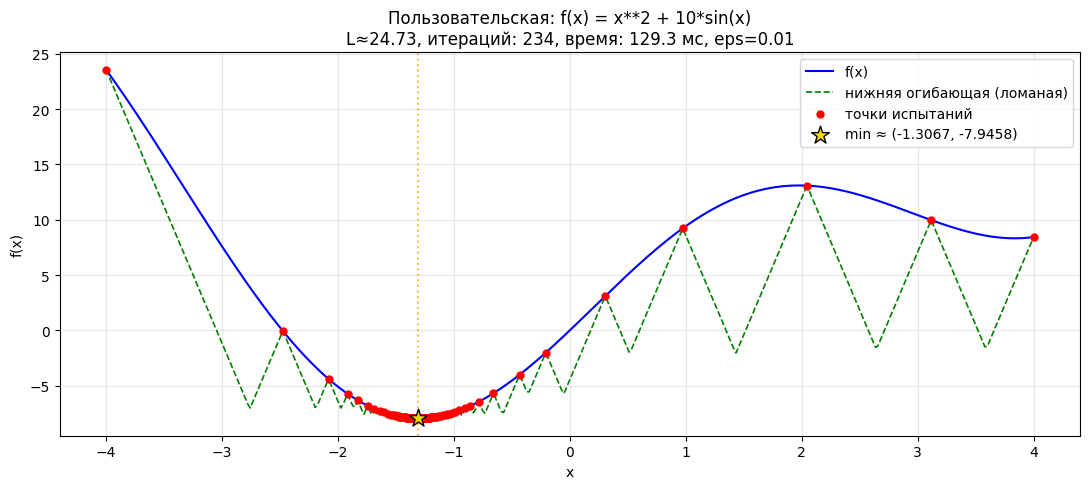

Приближённый аргумент минимума: x* ≈ -1.306661
Приближённое минимальное значение: f(x*) ≈ -7.945823
Число итераций: 234
Затраченное время: 129.33 мс
Оценка константы Липшица: L ≈ 24.7258
------------------------------------------------------------


In [ ]:
f_user, normalized = parse_function("x**2 + 10*sin(x)")
run_and_plot(f_user, -4, 4, eps=0.01,
             title=f"Пользовательская: f(x) = {normalized}")

# 3. Вывод
В ходе лабораторной работы был реализован метод ломаных (Пиявского) для поиска глобального минимума липшицевых функций на отрезке. Программа протестирована на двух 1D-срезах двумерных функций:

| Функция | Отрезок | $x^*$ | $f^*$ | Итераций | Время | $L$ |
|---|---|---|---|---|---|---|
| Растригин | $[-2, 2]$ | $\approx 0$ | $\approx 0$ | 127 | 2142 мс | 71.87 |
| Экли | $[-4, 4]$ | $\approx 0$ | $\approx 0$ | 16 | 34 мс | 9.41 |

Оба глобальных минимума найдены точно ($x^* = 0$, $f^* = 0$),
несмотря на наличие 5 локальных минимумов у Растригина и 7 внутренних локальных минимумов у Экли (точки $x = -3, -2, -1, 0, 1, 2, 3$) соответственно — что подтверждает корректность глобального поиска.